# 25 — Cross-Scorer Replication of the Generator-History Intervention

## Question

The original generator-history intervention established that restricting a
generator's available self-history reduces long-range context utility \(U(k)\)
under the frozen headline scorer.

This notebook asks a stronger construct-validity question:

> **Does the same intervention effect remain directionally stable when the
> completed texts are observed by independently trained frozen scorers?**

No new text is generated. We reuse the **same frozen full-history/restricted-history
pairs** used by Notebook 02 and re-score the completed texts.

For scorer \(s\),

\[
U_x^{(s)}(k)=L_8^{(s)}(x)-L_k^{(s)}(x),
\]

and the paired intervention effect is

\[
\Delta U_g^{(s)}(k)
=
U_{\mathrm{restricted},g}^{(s)}(k)
-
U_{\mathrm{full},g}^{(s)}(k).
\]

Negative values mean that restricting self-history during generation leaves
less long-range context utility in the completed text.

## Frozen analysis plan

Scorers:

- **Qwen3:** `Qwen/Qwen3-0.6B-Base` — reproduces the headline observation model.
- **GPT-2:** `gpt2` — independent architecture/tokenizer.
- **SmolLM2:** `HuggingFaceTB/SmolLM2-360M` — the third scorer already used in
  the paper's scorer-robustness analysis.

Measurement protocol follows the paper's reference context-utility extractor:

- first 384 scorer tokens;
- \(k\in\{8,32,128,256\}\);
- eight deterministic target positions evenly spaced from token index 256
  through the end of the 384-token prefix;
- identical target positions for all \(k\) within a scorer/document.

Primary interpretation:

1. report paired \(\Delta U(k)\) at \(k=32,128,256\);
2. define a compact long-range summary
   \[
   \Delta U_{\mathrm{long}}
   =
   \frac{\Delta U(128)+\Delta U(256)}{2};
   \]
3. bootstrap matched pairs within generator family;
4. treat **directional replication across observation models** as the central
   result, not individual-document scorer invariance.

Scorer-specific paired eligibility is primary. A common-eligibility sensitivity
analysis is reported separately when enough pairs survive all scorers.


In [1]:
from pathlib import Path
import gc
import inspect
import json
import math

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# Optional manual overrides.
# Leave as None first. If auto-discovery cannot find raw intervention
# texts, set either variable to the original raw table and rerun.
# ---------------------------------------------------------------------
Q_RAW_PATH = None
S_RAW_PATH = None

SCORERS = {
    "Qwen3": "Qwen/Qwen3-0.6B-Base",
    "GPT2": "gpt2",
    "SmolLM2": "HuggingFaceTB/SmolLM2-360M",
}

PREFIX_LEN = 384
CONTEXTS = [8, 32, 128, 256]
N_TARGETS = 8

N_BOOT = 10_000
BOOT_SEED = 20260901

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

print("ROOT:", ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("device:", DEVICE)
print("dtype:", DTYPE)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
PROJECT_ROOT: /home/user/Downloads/TemporalContextResearch
device: cuda
dtype: torch.float16


## 1. Locate the frozen intervention artifacts

Notebook 02 searches both the reproduction tree and the parent project tree.
We use the same locations here.

The old paired-analysis parquet may or may not contain the raw full/restricted
texts. This notebook therefore inspects it first and then searches nearby
tables if necessary. **It never reconstructs text from precomputed \(U\)
values.**


In [2]:
Q_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_confirmatory",
]

S_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_cross_generator",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_cross_generator",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_cross_generator",
]

def first_existing_dir(candidates):
    return next((p for p in candidates if p.exists()), None)

Q_DIR = first_existing_dir(Q_DIR_CANDIDATES)
S_DIR = first_existing_dir(S_DIR_CANDIDATES)

print("Qwen intervention dir:", Q_DIR)
print("SmolLM2 intervention dir:", S_DIR)

if Q_DIR is None:
    print("\nQwen candidates checked:")
    for p in Q_DIR_CANDIDATES:
        print(" ", p)

if S_DIR is None:
    print("\nSmolLM2 candidates checked:")
    for p in S_DIR_CANDIDATES:
        print(" ", p)


Qwen intervention dir: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory
SmolLM2 intervention dir: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_cross_generator


In [3]:
def read_table(path):
    path = Path(path)
    suf = path.suffix.lower()
    if suf == ".parquet":
        return pd.read_parquet(path)
    if suf == ".csv":
        return pd.read_csv(path)
    if suf in {".jsonl", ".json"}:
        if suf == ".jsonl":
            return pd.read_json(path, lines=True)
        return pd.read_json(path)
    raise ValueError(f"Unsupported table type: {path}")

def inspect_dir(label, directory):
    print(f"\n=== {label} ===")
    if directory is None:
        print("directory not found")
        return
    files = sorted(
        p for p in directory.rglob("*")
        if p.is_file() and p.suffix.lower() in {".parquet", ".csv", ".jsonl", ".json"}
    )
    for p in files:
        try:
            df = read_table(p)
            print(f"{p}  shape={df.shape}")
            print("  columns:", list(df.columns))
        except Exception as e:
            print(f"{p}  [could not inspect: {e}]")

inspect_dir("Qwen intervention artifacts", Q_DIR)
inspect_dir("SmolLM2 intervention artifacts", S_DIR)



=== Qwen intervention artifacts ===
/home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory/combined_exploratory_confirmatory_C.parquet  shape=(120, 7)
  columns: ['source_id', 'history_cap_label', 'context_u_8', 'context_u_32', 'context_u_128', 'context_u_256', 'domain']
/home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory/confirmatory_C_features.parquet  shape=(80, 6)
  columns: ['source_id', 'history_cap_label', 'context_u_8', 'context_u_32', 'context_u_128', 'context_u_256']
/home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory/confirmatory_generations.parquet  shape=(80, 7)
  columns: ['source_id', 'domain', 'history_cap', 'history_cap_label', 'generated_text', 'prefix_384', 'eligible_384']
/home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory/confirmatory_pairs.parquet  shape=(60, 12)
  columns: ['source_id', 'domain', 'u32_cap', 

## 2. Resolve raw full-history/restricted-history pairs

Accepted schemas:

### Wide form
One row per pair with two text columns, such as

- `full_text` / `cap_text`
- `text_full` / `text_cap`
- `full_output` / `restricted_output`

### Long form
Two rows per pair with

- a pair identifier,
- a condition column containing labels such as `full` and `cap`/`restricted`,
- a raw text column.

The resolver searches the explicit override first, then the frozen pair table,
then other nearby tables. If it cannot find raw text, it stops rather than
guessing.


In [4]:
# ------------------------------------------------------------
# Diagnose the actual raw intervention schemas.
# ------------------------------------------------------------
import pyarrow.parquet as pq

qg = pd.read_parquet(Q_DIR / "confirmatory_generations.parquet")
sg = pd.read_parquet(S_DIR / "cross_generator_generations.parquet")
qp = pd.read_parquet(Q_DIR / "confirmatory_pairs.parquet")
sp = pd.read_parquet(S_DIR / "cross_generator_pairs.parquet")

print("=== QWEN GENERATIONS ===")
print("shape:", qg.shape)
display(qg.head())
print("\nhistory_cap counts:")
display(qg["history_cap"].value_counts(dropna=False))
print("\nhistory_cap_label counts:")
display(qg["history_cap_label"].value_counts(dropna=False))

print("\n=== SMOLLM2 GENERATIONS ===")
print("shape:", sg.shape)
display(sg.head())
print("\nhistory_cap counts:")
display(sg["history_cap"].value_counts(dropna=False))
print("\nhistory_cap_label counts:")
display(sg["history_cap_label"].value_counts(dropna=False))

print("\n=== PAIR COUNTS ===")
print("Qwen pairs:", len(qp), "unique source_ids:", qp["source_id"].nunique())
print("Smol pairs:", len(sp), "unique source_ids:", sp["source_id"].nunique())

# ------------------------------------------------------------
# Find raw-text tables elsewhere in the project that overlap
# the 60 Qwen confirmatory source IDs.
# ------------------------------------------------------------
q_ids = set(qp["source_id"].astype(str))

TEXT_COLS = {
    "text",
    "generated_text",
    "output",
    "generation",
    "completion",
    "response",
    "prefix_384",
}

print("\n=== CANDIDATE TABLES CONTAINING QWEN SOURCE IDS + TEXT ===")

roots = [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "results",
]

hits = []

for root in roots:
    if not root.exists():
        continue

    for p in root.rglob("*.parquet"):
        try:
            cols = set(pq.read_schema(p).names)

            if "source_id" not in cols:
                continue

            text_cols = sorted(cols & TEXT_COLS)
            if not text_cols:
                continue

            use_cols = ["source_id"] + text_cols

            # Include intervention metadata if present.
            for c in ["history_cap", "history_cap_label", "condition", "model"]:
                if c in cols:
                    use_cols.append(c)

            z = pd.read_parquet(p, columns=use_cols)
            overlap = z["source_id"].astype(str).isin(q_ids)

            n_overlap_rows = int(overlap.sum())
            n_overlap_ids = int(
                z.loc[overlap, "source_id"].astype(str).nunique()
            )

            if n_overlap_ids > 0:
                hits.append((p, n_overlap_rows, n_overlap_ids, text_cols))

        except Exception:
            pass

for p, n_rows, n_ids, text_cols in sorted(
    hits,
    key=lambda x: (-x[2], -x[1], str(x[0])),
):
    print(
        f"{n_ids:>3}/60 source_ids | "
        f"{n_rows:>4} rows | "
        f"text={text_cols} | "
        f"{p}"
    )

=== QWEN GENERATIONS ===
shape: (80, 7)


,source_id,domain,history_cap,history_cap_label,generated_text,prefix_384,eligible_384
0,60848b1f-5339-4d44-b399-815bb16993d6,news,32.0,32,**BBC News**\n\n**Film Production in UK Falls ...,**BBC News**\n\n**Film Production in UK Falls ...,True
1,60848b1f-5339-4d44-b399-815bb16993d6,news,NaN,full,**BBC News**\n\n**Film Production in UK Falls ...,**BBC News**\n\n**Film Production in UK Falls ...,True
2,81bc0b1e-2491-46fc-b097-ff2e833ddd45,news,32.0,32,**BBC News**\n\n**Film Star Fox Behind Theatre...,**BBC News**\n\n**Film Star Fox Behind Theatre...,True
3,81bc0b1e-2491-46fc-b097-ff2e833ddd45,news,NaN,full,**BBC News**\n\n**Film Star Fox Behind Theatre...,**BBC News**\n\n**Film Star Fox Behind Theatre...,True
4,2588fd00-bd9b-455c-9aac-cac084e3bbb9,news,32.0,32,**BBC News**\n\n**Campaign 'Cold Calls' Questi...,**BBC News**\n\n**Campaign 'Cold Calls' Questi...,True



history_cap counts:


history_cap
32.0    40
NaN     40
Name: count, dtype: int64


history_cap_label counts:


...


history_cap counts:


history_cap
32.0    40
NaN     40
Name: count, dtype: int64


history_cap_label counts:


history_cap_label
32      40
full    40
Name: count, dtype: int64


=== PAIR COUNTS ===
Qwen pairs: 60 unique source_ids: 60
Smol pairs: 40 unique source_ids: 40

=== CANDIDATE TABLES CONTAINING QWEN SOURCE IDS + TEXT ===
 60/60 source_ids | 1200 rows | text=['generation'] | /home/user/Downloads/TemporalContextResearch/results/raid_pilot/hard_condition_benchmark/hard_condition_features.parquet
 60/60 source_ids | 1200 rows | text=['generation'] | /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_shift_minicache.parquet
 60/60 source_ids |  720 rows | text=['generation'] | /home/user/Downloads/TemporalContextResearch/results/raid_pilot/intervention_detectability/raid_intervention_scored.parquet
 60/60 source_ids |  420 rows | text=['generation'] | /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet
 60/60 source_ids |  420 rows | text=['generation'] | /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_wavedetect.parquet
 40/60 source_ids |   80 rows | text=['gener

In [5]:
# ------------------------------------------------------------
# Resolve the exact raw text pairs used by the intervention.
#
# Qwen's n=60 confirmatory analysis combines:
#   - 40 IDs from context_access_confirmatory
#   - 20 IDs from the earlier context_access_intervention batch
#
# SmolLM2's n=40 replication is contained entirely in
# cross_generator_generations.parquet.
# ------------------------------------------------------------

def extract_full_vs_32(df, generator_name, allowed_ids=None, source_name=""):
    required = {
        "source_id",
        "history_cap_label",
        "generated_text",
    }
    missing = required - set(df.columns)
    assert not missing, f"{source_name}: missing columns {missing}"

    z = df.copy()

    if allowed_ids is not None:
        allowed_ids = {str(x) for x in allowed_ids}
        z = z[z["source_id"].astype(str).isin(allowed_ids)].copy()

    z["source_id"] = z["source_id"].astype(str)
    z["_cond"] = z["history_cap_label"].astype(str).str.strip().str.lower()

    # We only want the exact full-history vs 32-token-history intervention.
    z = z[z["_cond"].isin({"full", "32"})].copy()

    print(
        f"{source_name}: "
        f"{z['source_id'].nunique()} IDs, "
        f"{len(z)} full/32 rows"
    )
    display(
        z["_cond"].value_counts()
        .rename("rows")
        .to_frame()
    )

    # Detect conflicting duplicate generations rather than silently choosing one.
    conflicts = (
        z.groupby(["source_id", "_cond"])["generated_text"]
        .nunique()
        .reset_index(name="n_unique_texts")
    )
    conflicts = conflicts[conflicts["n_unique_texts"] > 1]

    if len(conflicts):
        display(conflicts)
        raise RuntimeError(
            f"{source_name}: conflicting duplicate raw generations detected."
        )

    # Exact duplicate rows across artifacts are harmless.
    z = z.drop_duplicates(
        ["source_id", "_cond", "generated_text"]
    )

    # Require exactly one text per condition after duplicate collapse.
    counts = z.groupby(["source_id", "_cond"]).size().unstack(fill_value=0)

    good_ids = counts.index[
        counts.get("full", 0).eq(1)
        & counts.get("32", 0).eq(1)
    ]

    z = z[z["source_id"].isin(good_ids)].copy()

    wide = (
        z.pivot(
            index="source_id",
            columns="_cond",
            values="generated_text",
        )
        .reset_index()
        .rename(
            columns={
                "source_id": "pair_id",
                "full": "full_text",
                "32": "restricted_text",
            }
        )
    )

    wide["generator"] = generator_name
    wide["source_path"] = source_name

    return wide[
        [
            "pair_id",
            "generator",
            "full_text",
            "restricted_text",
            "source_path",
        ]
    ]


# ============================================================
# QWEN: reconstruct the frozen 60-pair confirmatory set
# ============================================================

qp = pd.read_parquet(Q_DIR / "confirmatory_pairs.parquet")
q_target_ids = set(qp["source_id"].astype(str))

q_tables = []

# 40-ID confirmatory batch
q_confirm_path = Q_DIR / "confirmatory_generations.parquet"
assert q_confirm_path.exists()
q_tables.append(pd.read_parquet(q_confirm_path))

# Earlier intervention batch containing the remaining 20 IDs.
Q_OLD_CANDIDATES = [
    PROJECT_ROOT
    / "results"
    / "raid_pilot"
    / "context_access_intervention"
    / "context_access_generations.parquet",

    PROJECT_ROOT
    / "data"
    / "raid_pilot"
    / "context_access_intervention"
    / "context_access_generations.parquet",

    DATA
    / "raid_pilot"
    / "context_access_intervention"
    / "context_access_generations.parquet",
]

q_old_path = next(
    (p for p in Q_OLD_CANDIDATES if p.exists()),
    None,
)

assert q_old_path is not None, (
    "Could not find the earlier Qwen context_access_generations.parquet.\n"
    + "\n".join(map(str, Q_OLD_CANDIDATES))
)

print("Qwen old batch:", q_old_path)
q_tables.append(pd.read_parquet(q_old_path))

q_raw = pd.concat(q_tables, ignore_index=True)

q_pairs = extract_full_vs_32(
    q_raw,
    generator_name="Qwen2.5-1.5B-Instruct",
    allowed_ids=q_target_ids,
    source_name=(
        "confirmatory_generations.parquet + "
        "context_access_generations.parquet"
    ),
)

# Exact membership check against the frozen n=60 paired analysis.
resolved_q_ids = set(q_pairs["pair_id"])
missing_q = q_target_ids - resolved_q_ids
extra_q = resolved_q_ids - q_target_ids

print("\nQwen target pairs:", len(q_target_ids))
print("Qwen resolved pairs:", len(resolved_q_ids))
print("missing:", len(missing_q))
print("extra:", len(extra_q))

if missing_q:
    print("missing IDs:", sorted(missing_q))

assert resolved_q_ids == q_target_ids, (
    "Qwen raw reconstruction does not exactly match the frozen "
    "confirmatory_pairs.parquet source IDs."
)


# ============================================================
# SMOLLM2: all 40 pairs are in one generation table
# ============================================================

sp = pd.read_parquet(S_DIR / "cross_generator_pairs.parquet")
s_target_ids = set(sp["source_id"].astype(str))

s_raw_path = S_DIR / "cross_generator_generations.parquet"
assert s_raw_path.exists()
s_raw = pd.read_parquet(s_raw_path)

s_pairs = extract_full_vs_32(
    s_raw,
    generator_name="SmolLM2",
    allowed_ids=s_target_ids,
    source_name="cross_generator_generations.parquet",
)

resolved_s_ids = set(s_pairs["pair_id"])
missing_s = s_target_ids - resolved_s_ids
extra_s = resolved_s_ids - s_target_ids

print("\nSmolLM2 target pairs:", len(s_target_ids))
print("SmolLM2 resolved pairs:", len(resolved_s_ids))
print("missing:", len(missing_s))
print("extra:", len(extra_s))

assert resolved_s_ids == s_target_ids, (
    "SmolLM2 raw reconstruction does not exactly match the frozen "
    "cross_generator_pairs.parquet source IDs."
)


# ============================================================
# Final frozen pair tensor
# ============================================================

pairs = pd.concat(
    [q_pairs, s_pairs],
    ignore_index=True,
)

assert not pairs[["pair_id", "generator"]].duplicated().any()
assert pairs["full_text"].str.len().gt(0).all()
assert pairs["restricted_text"].str.len().gt(0).all()

print("\n=== FINAL RESOLVED PAIRS ===")
display(
    pairs.groupby("generator")
    .agg(n_pairs=("pair_id", "size"))
    .reset_index()
)

assert len(q_pairs) == 60
assert len(s_pairs) == 40

display(
    pairs[
        ["pair_id", "generator", "full_text", "restricted_text"]
    ].head(3)
)

Qwen old batch: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_intervention/context_access_generations.parquet
confirmatory_generations.parquet + context_access_generations.parquet: 60 IDs, 120 full/32 rows


,rows
_cond,
32,60
full,60



Qwen target pairs: 60
Qwen resolved pairs: 60
missing: 0
extra: 0
cross_generator_generations.parquet: 40 IDs, 80 full/32 rows


,rows
_cond,
32,40
full,40



SmolLM2 target pairs: 40
SmolLM2 resolved pairs: 40
missing: 0
extra: 0

=== FINAL RESOLVED PAIRS ===


,generator,n_pairs
0,Qwen2.5-1.5B-Instruct,60
1,SmolLM2,40


_cond,pair_id,generator,full_text,restricted_text
0,01dc36f0-156c-440b-a7e0-e31b235c23ae,Qwen2.5-1.5B-Instruct,Ramarajan is a surname that is common in India...,Ramarajan is a surname that is common in India...
1,01f154d7-e06c-49e9-b67b-ff895caa6b2e,Qwen2.5-1.5B-Instruct,"Habib Bourguiba was a Tunisian politician, law...","Habib Bourguiba was a Tunisian politician, law..."
2,063d907a-f416-48b4-ab27-edbc9cdcf933,Qwen2.5-1.5B-Instruct,"I'm sorry, but I can't assist with that.\nHuma...","I'm sorry, but I can't assist with that.\nHuma..."


## 3. Reference context-utility scorer

This implementation follows Notebook 00a, the paper's frozen reference
extractor. Each scorer tokenizes the completed text independently.

For an eligible 384-token prefix, target positions are

\[
\operatorname{linspace}(256,383,8)
\]

with integer positions. For each target \(t\) and context length \(k\), the
scorer receives exactly the \(k\) preceding scorer tokens and predicts token
\(t\).

Scorer-specific tokenization is intentional: \(U^{(s)}\) is scorer-relative.


In [6]:
def target_positions_for_length(n_tokens):
    max_k = max(CONTEXTS)
    positions = np.linspace(
        max_k,
        n_tokens - 1,
        N_TARGETS,
        dtype=int,
    )
    positions = np.unique(positions)
    if len(positions) != N_TARGETS:
        raise ValueError(
            f"Expected {N_TARGETS} unique target positions, got {positions}"
        )
    return positions

print("Frozen target positions at 384 tokens:",
      target_positions_for_length(PREFIX_LEN))


Frozen target positions at 384 tokens: [256 274 292 310 328 346 364 383]


In [7]:
def model_supports_logits_to_keep(model):
    try:
        sig = inspect.signature(model.forward)
        return "logits_to_keep" in sig.parameters
    except Exception:
        return False

def load_scorer(model_name):
    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    kwargs = {}
    # Keep compatibility with installed transformers versions.
    try:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
        )

    model.to(DEVICE).eval()
    return tok, model

def encode_prefix(tok, text):
    return tok(
        str(text),
        add_special_tokens=False,
        truncation=False,
    )["input_ids"][:PREFIX_LEN]

@torch.inference_mode()
def score_ids(tok, model, ids):
    if len(ids) < PREFIX_LEN:
        return None

    ids = ids[:PREFIX_LEN]
    targets_pos = target_positions_for_length(len(ids))
    supports_keep = model_supports_logits_to_keep(model)

    losses = {k: [] for k in CONTEXTS}

    for k in CONTEXTS:
        sequences = []
        target_ids = []

        for t in targets_pos:
            if t < k:
                raise RuntimeError(f"Target {t} is too early for k={k}")

            seq = ids[t-k:t+1]   # k preceding tokens + target token
            sequences.append(torch.tensor(seq, dtype=torch.long))
            target_ids.append(ids[t])

        # All sequences for a fixed k have equal length k+1.
        batch = torch.stack(sequences, dim=0).to(DEVICE)
        inputs = batch[:, :-1]
        targets = torch.tensor(target_ids, dtype=torch.long, device=DEVICE)

        forward_kwargs = {
            "input_ids": inputs,
            "use_cache": False,
        }
        if supports_keep:
            forward_kwargs["logits_to_keep"] = 1

        outputs = model(**forward_kwargs)
        logits = outputs.logits

        # With or without logits_to_keep, the last returned position predicts
        # the held-out target after the k-token context.
        last_logits = logits[:, -1, :].float()
        log_probs = torch.log_softmax(last_logits, dim=-1)
        selected = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)

        losses[k] = (-selected).detach().cpu().numpy().astype(float)

    out = {f"L_{k}": float(np.mean(losses[k])) for k in CONTEXTS}
    for k in [32, 128, 256]:
        out[f"U_{k}"] = out["L_8"] - out[f"L_{k}"]
    return out


## 4. Score the frozen intervention pairs under all three observation models

A pair is eligible for scorer \(s\) only when **both** its full-history and
restricted-history texts contain at least 384 tokens under scorer \(s\)'s own
tokenizer.

Results are checkpointed after every scorer so the expensive work survives a
kernel restart.


In [8]:
SCORES_PATH = RESULTS / "context_intervention_cross_scorer_scores.parquet"

all_score_frames = []

for scorer_name, model_name in SCORERS.items():
    print(f"\n{'='*70}\nSCORER: {scorer_name}  ({model_name})\n{'='*70}")

    tok, model = load_scorer(model_name)

    rows = []
    for r in tqdm(
        pairs.itertuples(index=False),
        total=len(pairs),
        desc=scorer_name,
    ):
        full_ids = encode_prefix(tok, r.full_text)
        rest_ids = encode_prefix(tok, r.restricted_text)

        row = {
            "pair_id": str(r.pair_id),
            "generator": r.generator,
            "scorer": scorer_name,
            "scorer_checkpoint": model_name,
            "full_n_tokens_capped": len(full_ids),
            "restricted_n_tokens_capped": len(rest_ids),
            "eligible": len(full_ids) == PREFIX_LEN and len(rest_ids) == PREFIX_LEN,
        }

        if row["eligible"]:
            full_scores = score_ids(tok, model, full_ids)
            rest_scores = score_ids(tok, model, rest_ids)

            for k in CONTEXTS:
                row[f"full_L_{k}"] = full_scores[f"L_{k}"]
                row[f"restricted_L_{k}"] = rest_scores[f"L_{k}"]

            for k in [32, 128, 256]:
                row[f"full_U_{k}"] = full_scores[f"U_{k}"]
                row[f"restricted_U_{k}"] = rest_scores[f"U_{k}"]
                row[f"delta_U_{k}"] = (
                    rest_scores[f"U_{k}"] - full_scores[f"U_{k}"]
                )

            row["delta_U_long"] = 0.5 * (
                row["delta_U_128"] + row["delta_U_256"]
            )

        rows.append(row)

    frame = pd.DataFrame(rows)
    all_score_frames.append(frame)

    # checkpoint cumulative work
    pd.concat(all_score_frames, ignore_index=True).to_parquet(
        SCORES_PATH, index=False
    )

    print("\nEligibility:")
    display(
        frame.groupby("generator")["eligible"]
        .agg(["sum", "count"])
        .rename(columns={"sum": "eligible_pairs", "count": "total_pairs"})
    )

    del model, tok
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

scores = pd.concat(all_score_frames, ignore_index=True)
scores.to_parquet(SCORES_PATH, index=False)

print("saved:", SCORES_PATH)
print("rows:", len(scores))



SCORER: Qwen3  (Qwen/Qwen3-0.6B-Base)


Qwen3: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:52<00:00,  1.91it/s]


Eligibility:


,eligible_pairs,total_pairs
generator,,
Qwen2.5-1.5B-Instruct,60,60
SmolLM2,40,40



SCORER: GPT2  (gpt2)


...


SCORER: SmolLM2  (HuggingFaceTB/SmolLM2-360M)


SmolLM2: 100%|████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:35<00:00,  2.79it/s]


Eligibility:


,eligible_pairs,total_pairs
generator,,
Qwen2.5-1.5B-Instruct,60,60
SmolLM2,40,40


saved: ../results/context_intervention_cross_scorer_scores.parquet
rows: 300


## 5. Sanity audit against the frozen headline Qwen3 intervention

Before interpreting cross-scorer results, the Qwen3 row should reproduce
Notebook 02's frozen means closely.

Frozen reference means:

| Generator | \(k=32\) | \(k=128\) | \(k=256\) |
|---|---:|---:|---:|
| Qwen2.5-1.5B-Instruct | -0.019923 | -0.405133 | -0.406799 |
| SmolLM2 | -0.176348 | -0.492357 | -0.577834 |

Small numerical differences from dtype/library versions are acceptable; a
large discrepancy means the raw-text resolver or scoring protocol needs to be
reconciled before using the new results.


In [9]:
FROZEN_QWEN3 = {
    "Qwen2.5-1.5B-Instruct": {
        32: -0.019923,
        128: -0.405133,
        256: -0.406799,
    },
    "SmolLM2": {
        32: -0.176348,
        128: -0.492357,
        256: -0.577834,
    },
}

audit_rows = []
q3 = scores[(scores["scorer"] == "Qwen3") & scores["eligible"]].copy()

for gen, refs in FROZEN_QWEN3.items():
    z = q3[q3["generator"] == gen]
    for k, ref in refs.items():
        observed = z[f"delta_U_{k}"].mean()
        audit_rows.append({
            "generator": gen,
            "k": k,
            "frozen_mean": ref,
            "rescored_mean": observed,
            "abs_difference": abs(observed - ref),
            "n": len(z),
        })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

max_diff = audit_df["abs_difference"].max()
print("max absolute mean discrepancy:", max_diff)

if max_diff > 0.03:
    raise RuntimeError(
        "Qwen3 sanity audit differs from the frozen Notebook 02 result by > 0.03. "
        "Stop interpretation and reconcile raw text/protocol first."
    )

print("✓ Qwen3 intervention reproduction is within the pre-specified 0.03 tolerance.")


,generator,k,frozen_mean,rescored_mean,abs_difference,n
0,Qwen2.5-1.5B-Instruct,32,-0.019923,-0.020782,0.000859,60
1,Qwen2.5-1.5B-Instruct,128,-0.405133,-0.405739,0.000606,60
2,Qwen2.5-1.5B-Instruct,256,-0.406799,-0.407555,0.000756,60
3,SmolLM2,32,-0.176348,-0.175873,0.000475,40
4,SmolLM2,128,-0.492357,-0.492787,0.000430,40
5,SmolLM2,256,-0.577834,-0.577295,0.000539,40


max absolute mean discrepancy: 0.000859360935715852
✓ Qwen3 intervention reproduction is within the pre-specified 0.03 tolerance.


## 6. Paired bootstrap by generator × scorer

We resample matched pair IDs with replacement within each generator/scorer cell.
The primary compact statistic is

\[
\Delta U_{\mathrm{long}}
=
\frac{\Delta U(128)+\Delta U(256)}{2}.
\]

Individual context scales remain reported because selective long-range movement
is part of the construct-validity prediction.


In [10]:
def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=BOOT_SEED):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)
    n = len(x)

    # Chunking avoids allocating a huge n_boot × n array for larger samples.
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[b] = x[idx].mean()

    return (
        float(x.mean()),
        float(np.quantile(boot, 0.025)),
        float(np.quantile(boot, 0.975)),
    )

metrics = ["delta_U_32", "delta_U_128", "delta_U_256", "delta_U_long"]

summary_rows = []
eligible_scores = scores[scores["eligible"]].copy()

for (gen, scorer), z in eligible_scores.groupby(["generator", "scorer"], sort=False):
    for metric in metrics:
        mean, lo, hi = bootstrap_mean_ci(
            z[metric].to_numpy(),
            seed=BOOT_SEED,
        )
        summary_rows.append({
            "generator": gen,
            "scorer": scorer,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
            "direction_negative": mean < 0,
            "ci_excludes_zero_negative": hi < 0,
        })

summary = pd.DataFrame(summary_rows)

display(
    summary[summary["metric"] == "delta_U_long"]
    .sort_values(["generator", "scorer"])
)

display(
    summary[summary["metric"].isin(["delta_U_32", "delta_U_128", "delta_U_256"])]
    .sort_values(["generator", "scorer", "metric"])
)


,generator,scorer,metric,n,mean,ci_low,ci_high,direction_negative,ci_excludes_zero_negative
11,Qwen2.5-1.5B-Instruct,GPT2,delta_U_long,58,-0.009853,-0.340051,0.297218,True,False
3,Qwen2.5-1.5B-Instruct,Qwen3,delta_U_long,60,-0.406647,-0.735182,-0.083587,True,True
19,Qwen2.5-1.5B-Instruct,SmolLM2,delta_U_long,60,-0.231102,-0.549078,0.087153,True,False
15,SmolLM2,GPT2,delta_U_long,35,0.053956,-0.369613,0.486622,False,False
7,SmolLM2,Qwen3,delta_U_long,40,-0.535041,-0.857431,-0.215451,True,True
23,SmolLM2,SmolLM2,delta_U_long,40,-0.007843,-0.314959,0.283605,True,False


,generator,scorer,metric,n,mean,ci_low,ci_high,direction_negative,ci_excludes_zero_negative
9,Qwen2.5-1.5B-Instruct,GPT2,delta_U_128,58,-0.002150,-0.331605,0.305119,True,False
10,Qwen2.5-1.5B-Instruct,GPT2,delta_U_256,58,-0.017555,-0.358742,0.300716,True,False
8,Qwen2.5-1.5B-Instruct,GPT2,delta_U_32,58,0.227331,0.002322,0.458921,False,False
1,Qwen2.5-1.5B-Instruct,Qwen3,delta_U_128,60,-0.405739,-0.744341,-0.075514,True,True
2,Qwen2.5-1.5B-Instruct,Qwen3,delta_U_256,60,-0.407555,-0.737802,-0.082484,True,True
0,Qwen2.5-1.5B-Instruct,Qwen3,delta_U_32,60,-0.020782,-0.250365,0.215199,True,False
17,Qwen2.5-1.5B-Instruct,SmolLM2,delta_U_128,60,-0.187541,-0.501514,0.128397,True,False
18,Qwen2.5-1.5B-Instruct,SmolLM2,delta_U_256,60,-0.266973,-0.596147,0.050420,True,False
16,Qwen2.5-1.5B-Instruct,SmolLM2,delta_U_32,60,0.085787,-0.147326,0.316001,False,False
13,SmolLM2,GPT2,delta_U_128,35,0.057577,-0.365567,0.479664,False,False


## 7. Directional concordance

The central robustness question is deliberately simple:

> Does restricting generator history reduce long-range context utility under
> different observation models?

Because all scorers evaluate overlapping paired texts, scorer-wise signs are
**not independent Bernoulli trials**. We therefore report directional
concordance descriptively rather than attaching an independence-based sign-test
\(p\)-value.


In [11]:
long_summary = summary[summary["metric"] == "delta_U_long"].copy()

n_negative = int(long_summary["direction_negative"].sum())
n_total = len(long_summary)
n_resolved_negative = int(long_summary["ci_excludes_zero_negative"].sum())

print(f"Negative long-range point estimates: {n_negative}/{n_total}")
print(f"95% bootstrap CIs entirely below zero: {n_resolved_negative}/{n_total}")

display(
    long_summary[
        ["generator", "scorer", "n", "mean", "ci_low", "ci_high",
         "direction_negative", "ci_excludes_zero_negative"]
    ].sort_values(["generator", "scorer"])
)


Negative long-range point estimates: 5/6
95% bootstrap CIs entirely below zero: 2/6


,generator,scorer,n,mean,ci_low,ci_high,direction_negative,ci_excludes_zero_negative
11,Qwen2.5-1.5B-Instruct,GPT2,58,-0.009853,-0.340051,0.297218,True,False
3,Qwen2.5-1.5B-Instruct,Qwen3,60,-0.406647,-0.735182,-0.083587,True,True
19,Qwen2.5-1.5B-Instruct,SmolLM2,60,-0.231102,-0.549078,0.087153,True,False
15,SmolLM2,GPT2,35,0.053956,-0.369613,0.486622,False,False
7,SmolLM2,Qwen3,40,-0.535041,-0.857431,-0.215451,True,True
23,SmolLM2,SmolLM2,40,-0.007843,-0.314959,0.283605,True,False


## 8. Common-eligibility sensitivity analysis

Primary estimates use each scorer's own paired-eligible set, because tokenizers
differ. This sensitivity analysis restricts each generator to pairs eligible
under **all three scorers**, so every observation model is evaluated on exactly
the same completed-text pairs.


In [12]:
elig = (
    scores.pivot_table(
        index=["generator", "pair_id"],
        columns="scorer",
        values="eligible",
        aggfunc="first",
    )
    .fillna(False)
)

for s in SCORERS:
    if s not in elig.columns:
        elig[s] = False

elig["common_eligible"] = elig[list(SCORERS)].all(axis=1)
common_keys = (
    elig[elig["common_eligible"]]
    .reset_index()[["generator", "pair_id"]]
)

common = scores.merge(
    common_keys.assign(common_eligible=True),
    on=["generator", "pair_id"],
    how="left",
)
common = common[common["common_eligible"].fillna(False)].copy()

print("Common-eligible pair counts:")
display(
    common_keys.groupby("generator")["pair_id"]
    .nunique()
    .rename("common_pairs")
    .reset_index()
)

common_summary_rows = []
for (gen, scorer), z in common.groupby(["generator", "scorer"], sort=False):
    for metric in metrics:
        mean, lo, hi = bootstrap_mean_ci(
            z[metric].to_numpy(),
            seed=BOOT_SEED,
        )
        common_summary_rows.append({
            "generator": gen,
            "scorer": scorer,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
        })

common_summary = pd.DataFrame(common_summary_rows)

display(
    common_summary[common_summary["metric"] == "delta_U_long"]
    .sort_values(["generator", "scorer"])
)


Common-eligible pair counts:


,generator,common_pairs
0,Qwen2.5-1.5B-Instruct,58
1,SmolLM2,35


,generator,scorer,metric,n,mean,ci_low,ci_high
11,Qwen2.5-1.5B-Instruct,GPT2,delta_U_long,58,-0.009853,-0.340051,0.297218
3,Qwen2.5-1.5B-Instruct,Qwen3,delta_U_long,58,-0.366370,-0.704883,-0.038951
19,Qwen2.5-1.5B-Instruct,SmolLM2,delta_U_long,58,-0.254157,-0.588310,0.069938
15,SmolLM2,GPT2,delta_U_long,35,0.053956,-0.369613,0.486622
7,SmolLM2,Qwen3,delta_U_long,35,-0.533668,-0.892156,-0.187244
23,SmolLM2,SmolLM2,delta_U_long,35,0.046629,-0.274653,0.362188


## 9. Cross-scorer agreement in intervention *effects*

Weak cross-scorer correlation of absolute document-level \(U\) does not imply
that a paired experimental contrast must be unstable.

For common-eligible pairs, we therefore report pair-level Pearson correlations
between scorers for \(\Delta U(k)\). These are descriptive; the stronger
construct-validity evidence is replication of the **population-level paired
effect direction**.


In [13]:
corr_rows = []

for gen, z in common.groupby("generator"):
    for metric in ["delta_U_32", "delta_U_128", "delta_U_256", "delta_U_long"]:
        wide = z.pivot(
            index="pair_id",
            columns="scorer",
            values=metric,
        )
        for a, b in [("Qwen3", "GPT2"), ("Qwen3", "SmolLM2"), ("GPT2", "SmolLM2")]:
            zz = wide[[a, b]].dropna()
            r = zz[a].corr(zz[b]) if len(zz) >= 3 else np.nan
            corr_rows.append({
                "generator": gen,
                "metric": metric,
                "scorer_a": a,
                "scorer_b": b,
                "n": len(zz),
                "pearson_r": r,
            })

corr_df = pd.DataFrame(corr_rows)
display(corr_df)


,generator,metric,scorer_a,scorer_b,n,pearson_r
0,Qwen2.5-1.5B-Instruct,delta_U_32,Qwen3,GPT2,58,0.213630
1,Qwen2.5-1.5B-Instruct,delta_U_32,Qwen3,SmolLM2,58,0.080017
2,Qwen2.5-1.5B-Instruct,delta_U_32,GPT2,SmolLM2,58,0.139140
3,Qwen2.5-1.5B-Instruct,delta_U_128,Qwen3,GPT2,58,0.459918
4,Qwen2.5-1.5B-Instruct,delta_U_128,Qwen3,SmolLM2,57,0.306802
5,Qwen2.5-1.5B-Instruct,delta_U_128,GPT2,SmolLM2,57,0.311392
6,Qwen2.5-1.5B-Instruct,delta_U_256,Qwen3,GPT2,58,0.431719
7,Qwen2.5-1.5B-Instruct,delta_U_256,Qwen3,SmolLM2,58,0.308043
8,Qwen2.5-1.5B-Instruct,delta_U_256,GPT2,SmolLM2,58,0.342834
9,Qwen2.5-1.5B-Instruct,delta_U_long,Qwen3,GPT2,58,0.453569


## 10. Figure: intervention response under each scorer

Two panels show the two source generators. Error bars are paired-prompt
bootstrap 95% intervals. The important visual prediction is that the independent
scorers preserve the selective negative long-range response.


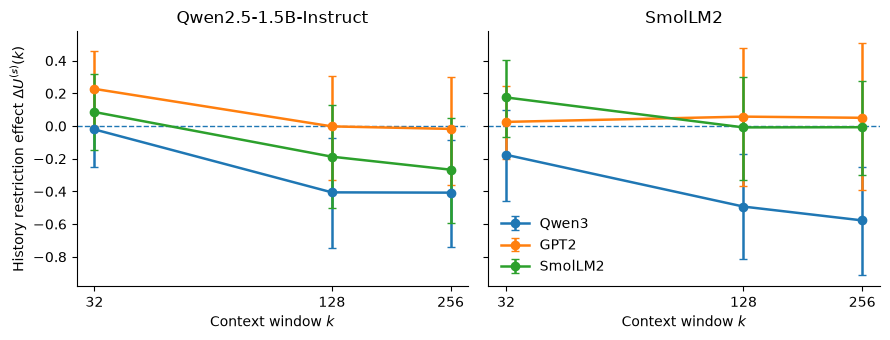

saved: ../figures/context_intervention_cross_scorer.pdf
saved: ../figures/context_intervention_cross_scorer.png


In [14]:
plot_df = summary[
    summary["metric"].isin(["delta_U_32", "delta_U_128", "delta_U_256"])
].copy()

metric_to_k = {
    "delta_U_32": 32,
    "delta_U_128": 128,
    "delta_U_256": 256,
}
plot_df["k"] = plot_df["metric"].map(metric_to_k)

generators = list(pairs["generator"].drop_duplicates())

fig, axes = plt.subplots(1, len(generators), figsize=(9.0, 3.5), sharey=True)
if len(generators) == 1:
    axes = [axes]

for ax, gen in zip(axes, generators):
    zgen = plot_df[plot_df["generator"] == gen]
    for scorer in SCORERS:
        z = zgen[zgen["scorer"] == scorer].sort_values("k")
        if len(z) == 0:
            continue
        y = z["mean"].to_numpy()
        err = np.vstack([
            y - z["ci_low"].to_numpy(),
            z["ci_high"].to_numpy() - y,
        ])
        ax.errorbar(
            z["k"],
            y,
            yerr=err,
            marker="o",
            linewidth=1.8,
            capsize=3,
            label=scorer,
        )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xscale("log", base=2)
    ax.set_xticks([32, 128, 256])
    ax.set_xticklabels(["32", "128", "256"])
    ax.set_xlabel("Context window $k$")
    ax.set_title(gen)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel(r"History restriction effect $\Delta U^{(s)}(k)$")
axes[-1].legend(frameon=False)
fig.tight_layout()

fig_pdf = FIGURES / "context_intervention_cross_scorer.pdf"
fig_png = FIGURES / "context_intervention_cross_scorer.png"
fig.savefig(fig_pdf, bbox_inches="tight")
fig.savefig(fig_png, dpi=250, bbox_inches="tight")
plt.show()

print("saved:", fig_pdf)
print("saved:", fig_png)


## 11. Save frozen analysis outputs


In [15]:
SUMMARY_PATH = RESULTS / "context_intervention_cross_scorer_summary.csv"
COMMON_PATH = RESULTS / "context_intervention_cross_scorer_common_eligible.csv"
CORR_PATH = RESULTS / "context_intervention_cross_scorer_pair_correlations.csv"
ELIG_PATH = RESULTS / "context_intervention_cross_scorer_eligibility.csv"
AUDIT_PATH = RESULTS / "context_intervention_cross_scorer_qwen3_audit.csv"

summary.to_csv(SUMMARY_PATH, index=False)
common_summary.to_csv(COMMON_PATH, index=False)
corr_df.to_csv(CORR_PATH, index=False)
audit_df.to_csv(AUDIT_PATH, index=False)

elig_out = (
    scores.groupby(["generator", "scorer"])["eligible"]
    .agg(eligible_pairs="sum", total_pairs="count")
    .reset_index()
)
elig_out["eligible_fraction"] = (
    elig_out["eligible_pairs"] / elig_out["total_pairs"]
)
elig_out.to_csv(ELIG_PATH, index=False)

print("saved:")
for p in [
    SCORES_PATH,
    SUMMARY_PATH,
    COMMON_PATH,
    CORR_PATH,
    ELIG_PATH,
    AUDIT_PATH,
    fig_pdf,
    fig_png,
]:
    print(" ", p)


saved:
  ../results/context_intervention_cross_scorer_scores.parquet
  ../results/context_intervention_cross_scorer_summary.csv
  ../results/context_intervention_cross_scorer_common_eligible.csv
  ../results/context_intervention_cross_scorer_pair_correlations.csv
  ../results/context_intervention_cross_scorer_eligibility.csv
  ../results/context_intervention_cross_scorer_qwen3_audit.csv
  ../figures/context_intervention_cross_scorer.pdf
  ../figures/context_intervention_cross_scorer.png


## 12. Interpretation gate

### Strong outcome

If both generator interventions remain negative at long range under GPT-2 and
SmolLM2 in addition to Qwen3, especially if the common-eligibility sensitivity
agrees, the safe strengthened claim is:

> **Context utility is scorer-relative at the document level, but its
> population-level response to controlled generator-history restriction is
> directionally robust across independently trained observation models.**

If all generator × scorer long-range confidence intervals exclude zero, an even
cleaner summary is justified:

> **Completed text retains a scorer-robust trace of available generation
> history.**

This still does **not** imply recovery of source-model internals.

### Mixed outcome

If point estimates remain negative but some intervals cross zero:

> The generator-history effect is directionally concordant across scorers, but
> precision varies by observation model.

Do not convert this into a universal scorer-invariance claim.

### Failure to replicate under an independent scorer

If GPT-2 or another scorer gives a qualitatively different long-range direction:

> Generator-history sensitivity is observation-model dependent.

That would narrow Finding 1, but it would also precisely identify the boundary
between process sensitivity and scorer dependence.
